Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
2014-04-07T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,0.0,0.0,0.0,0.0,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,WI
2014-04-08T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,null,null,null,0.0,1.0030591666666666,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,OP
2014-04-09T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,null,null,null,0.0,0.9790077083333333,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,OP
2014-04-10T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,null,null,null,0.0,0.5457591666666667,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,OP
2014-04-11T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,96.87589,277.27826,0.0,1.215986875,%,33.09788,10.47992,33.07195,0.0,0.0,0.0,null,production,OP


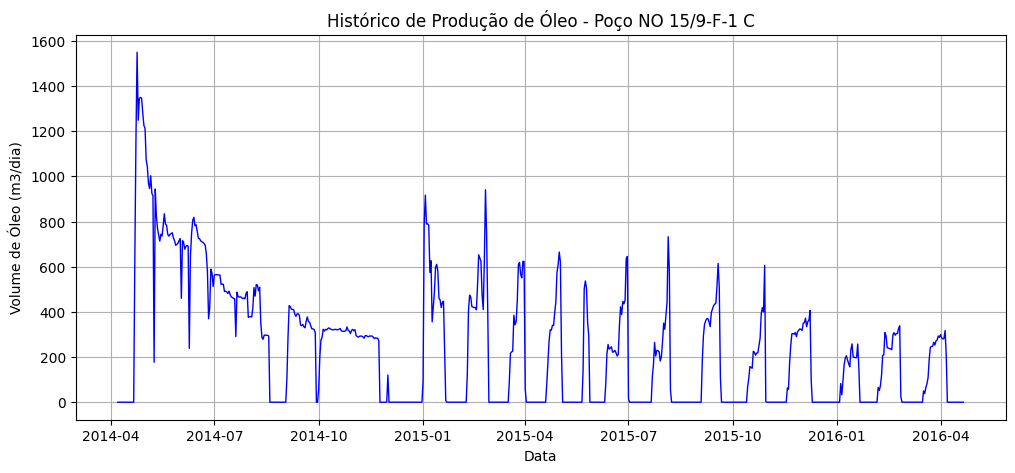

DATEPRD,DIAS_PRODUCAO,BORE_OIL_VOL
2014-04-22T00:00:00.000Z,0,631.47
2014-04-23T00:00:00.000Z,1,1166.46
2014-04-24T00:00:00.000Z,2,1549.81
2014-04-25T00:00:00.000Z,3,1248.7
2014-04-26T00:00:00.000Z,4,1345.78


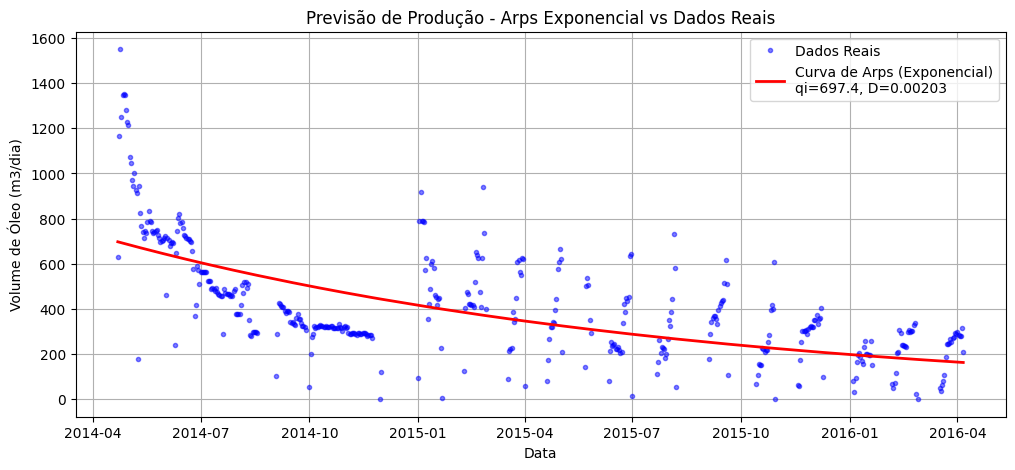

--- Estatísticas Descritivas da Produção de Óleo ---


count     746.000000
mean      238.216260
std       275.735496
min         0.000000
25%         0.000000
50%       200.685000
75%       384.605000
max      1549.810000
Name: BORE_OIL_VOL, dtype: float64

In [0]:
%pip install openpyxl
import pandas as pd

# Caminho completo para o ficheiro de produção de Volve
caminho_arquivo = "/Volumes/equinor_asa_volve_data_village/public/volve/Production_data/Volve production data.xlsx"

# Lê a aba de dados diários de produção
df = pd.read_excel(caminho_arquivo, sheet_name="Daily Production Data")

# Mostra as primeiras linhas da tabela
display(df.head())
import matplotlib.pyplot as plt

# Filtrar os dados para um poço específico (ex: NO 15/9-F-1 C)
df['DATEPRD'] = pd.to_datetime(df['DATEPRD'])
df_poco = df[df['WELL_BORE_CODE'] == 'NO 15/9-F-1 C']

# Criar o gráfico da taxa de produção de óleo ao longo do tempo
plt.figure(figsize=(12, 5))
plt.plot(df_poco['DATEPRD'], df_poco['BORE_OIL_VOL'], color='blue', linewidth=1)
plt.title('Histórico de Produção de Óleo - Poço NO 15/9-F-1 C')
plt.xlabel('Data')
plt.ylabel('Volume de Óleo (m3/dia)')
plt.grid(True)
plt.show()
import pandas as pd

# 1. Filtrar apenas os dias em que houve produção efetiva de óleo (remover dias com zero ou negativos)
df_declive = df_poco[df_poco['BORE_OIL_VOL'] > 0].copy()

# 2. Criar uma coluna de tempo acumulado em dias a partir da primeira data de produção do poço
df_declive['DIAS_PRODUCAO'] = (df_declive['DATEPRD'] - df_declive['DATEPRD'].min()).dt.days

# 3. Mostrar as primeiras linhas do novo DataFrame preparado
display(df_declive[['DATEPRD', 'DIAS_PRODUCAO', 'BORE_OIL_VOL']].head())
import numpy as np
from scipy.optimize import curve_fit

# 1. Preparar os dados para o ajuste (remover eventuais NaNs)
df_Arps = df_declive.dropna(subset=['DIAS_PRODUCAO', 'BORE_OIL_VOL']).copy()
xData = df_Arps['DIAS_PRODUCAO'].values
yData = df_Arps['BORE_OIL_VOL'].values

# 2. Definir a equação do Declínio Exponencial de Arps: q(t) = qi * exp(-D * t)
def arps_exponential(t, qi, D):
    return qi * np.exp(-D * t)

# 3. Ajustar a curva aos dados reais (estimando qi inicial e taxa D)
popt, pcov = curve_fit(arps_exponential, xData, yData, p0=[yData[0], 0.001])
qi_est, D_est = popt

# 4. Gerar a curva prevista
y_pred = arps_exponential(xData, qi_est, D_est)

# 5. Visualizar o resultado (Dados reais vs Curva de Arps)
plt.figure(figsize=(12, 5))
plt.plot(df_Arps['DATEPRD'], yData, '.', color='blue', label='Dados Reais', alpha=0.5)
plt.plot(df_Arps['DATEPRD'], y_pred, color='red', linewidth=2, label=f'Curva de Arps (Exponencial)\nqi={qi_est:.1f}, D={D_est:.5f}')
plt.title('Previsão de Produção - Arps Exponencial vs Dados Reais')
plt.xlabel('Data')
plt.ylabel('Volume de Óleo (m3/dia)')
plt.legend()
plt.grid(True)
plt.show()
# Estatísticas descritivas básicas do poço de estudo
print("--- Estatísticas Descritivas da Produção de Óleo ---")
display(df_poco['BORE_OIL_VOL'].describe())